# AWS MM Router — Implementation & Preliminary Results

**Adaptive routing improves median latency and SLO attainment, while ECT retains a slight advantage in tail latency.**

100 mixed-modality requests per policy · RR vs. ECT vs. Adaptive · one experimental run.


## 1. What we built

- **Adaptive routing:** Stage-aware latency prediction, concurrent-interference modeling, and SLO-aware node selection.
- **Scheduling refinement:** Prioritize feasible, timely completion without ignoring the impact on running requests.
- **Runtime adaptation:** Calibration reuse, concurrent request execution, centralized queueing, and online feedback.
- **Validation:** Regression tests for prediction, scheduling, and replay.


## 2. System at a glance

Two CPU inference workers (**AMD c7a.2xlarge**, **Intel c7i.2xlarge**), each with two serving slots. A separate router runs RR, ECT, or Adaptive over Qwen2.5-Omni-3B.

**Current scope:** Each request executes on one worker. KV-cache transfer and prefill/decode split experiments are separate, not yet part of live routing.


## 3. Evaluation

| Setup | Value |
|---|---|
| Requests | 100 per policy; identical mixed-modality workload |
| Mix | 44 chat · 22 text · 19 image · 15 audio |
| Workers | AMD + Intel; two slots each |
| Metrics | E2E latency, TTFT, SLO attainment, node allocation |

**One run per policy:** the comparisons below show preliminary trends, not statistical significance.


In [1]:
import base64, gzip, io, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Self-contained experimental data.
DATA = {
    'requests.csv': '...',
    'summary.csv': 'H4sIAA/6CWsC/8WY3W4juRWE7xfYJwndIA//5zn2am8Exe6ZCLEtRW4tNm+fr6gfW7ZnNotgFUk2ZJrdTRbrVBW5PzyvNg9u2TzNL8v6abc6LPfu/vHwssx7t+zX97PbbR839/92L/P84LaHZXdYVk/bh9ltv36d9/PDaj//a/Xivu23h53j+4EbvbiXw/39/PLivq43j1z3ND9s1s+r2Wa67nq+fOunb6cOy/J1OfU4fT39g9se1O/4sMPLw2o371fhn6vLE3fzmr/WT6tvf3f3u8Nqd7+4++3T7nFeNtvn1cvjdrVelvXm+Wl+Xtzx7u/adtsPbdvf5v368fFd888/mbcSgtVfQo/ep1+dGu5CuKPJ/Bdfv/jyN88X79ZPD3eb52V+HHM5PN0JyWRuv3fePa+XAw9wfvKphBhjrcG6teJDcTzYBe6gH37nqdAnt1S655WLq35qtbXae6yJYUS6tinx7xxz8Cn4UlybYg05x5RS7712l+NUu1nzoVbuE4KzqefEPLhDDfTNNt/5PAaVffEtFvrHVhk1Lz/16PRkfeOnthvhcf+P9eJS0kegTDnxlJatZ+9jyy7ZZIzUtx5aZqpckhkic/aWkjH7pEklIMzAVmhoPbsYpsoFFvmLtshY4uQttAEODT6WcgYk9GallmbcJTPGekYktLdvwVLt6u3C5D9pvhF2y/z74sz08c7qFFtnVjwIUrToWp+gTm0l98S7F/BNU7IaC7P0kCAxgTLVFFspocQsbPLgUugAGlqiLeQkMpVS+b/lGlPJ6YKd751h0dcYFnjHE3Y5vX2XE1DtGlH7pOlG2G2e1t9mF7o+gCfGR0rLQoEh0cMyaqwEiqr62PVyLU+QpEeqLBpQUZk2VYouRD66LFdnfYopdmMZrEFOE3ilp6A6TT3CRmsX8Fqm+HMHY8s8TdgJqBNYPbFULVnw2Uq0T5puJVqHh80WsdLHa4qVZ0KmLLB8r67FqQFeC4lxiSVQDfaVbLU2o7BcAM4ExtnSEKjsCnD6BiShcJlXgQYKmH9ayBHipgtMUK8HQ++4voWQjhxrp58ar180lVupV11P9vvjeg+XstfHixToaqyRWaii4FLMFERBnLiDFNtcThPq7VMKzF69XJ08qk8RNq8enaqeKK1ecqHoYFKTglHYR5/IleefATLY41WuzBjbgEdg2wOFCnAsQZS6XnjVBVoXnfrNYNp8gImSY+1Bw7OygxA9TEHEAocs+TfHwCZqjZqJzffgJbiwhFuDB8UDMzJEQq8auKSSxK3GA21qUc5I3UGX5u2HSGkd8AOE0s5IwawiaulXE17lLaXMi/7vsUr1S/Z/gNVMgvlzCQHFzgnbgwiaUG3yP59TMyZXQ0KoXWGQCbollrwAU3cF9+rQxBfhYCU7SxSSnADbBF1CRJoiYACiR+UCSL0GhOwrCYSH0D+e7VC5oKfXqHArQD5GBC18j5Ll7OOQFi6qKAl1g0JWl/wUce+E+8ETQhF3Ngje8TUVIGvd0KQpGr6V6YLs4IlAkpi5cC7A22q88AY6YnxVRGVw58x0bfwDllbim3f6Tq+rTvFm3LpODJDEIy0sdx0pchBJclxKUtqUjpcyITYNk4IhqlXpm9IkKWNA2ZXITA9rJK6QpEuDW2QqeWJB9SnGS9ZSxkCxWULMlCI7Wd4nkYEmf/UO/0fkrvNC6AhCpUJ4tOrHXIqTUhS2hZyJmC7XyQAX/8s+h66shcApPAx8EVvmiMjTIRAxRpblWlSeBZDKJ0/+IBK9pgX2CokIHJTrY/tf0sJfq2DXcSFSVMSBBnv6CKYR9ChECEWIYtLUa2WwlQpVbqoDq0buj/iAao7iJEYFKFJjr7koTREHxDL+lszjpV3EfY0M0A86ckeyP2x+B1a5etVPmm6mbm8iRM36DNE36VmX9UmtUKbCxSb7SlVVh6KTIXxNLQoKdki+DdWnBMlI592k+CVIqy4WwX6AGfYRVWZYCONjrjLH5hVkADOFMdw3MWJU6Mfs1d613Q7I15BBGdkAEvWC/ACoxO6Zh8udoGUV0VOG0IVIXCTKaqNosUjiMBSuiOAmqAHOJa6qmKU0ED+xdPQKU/VnUpuFXi8Shxdh1504xyqyG/h+yOiXfDHyWLvCKhNzrrEKX2ICpT/Aav2w3i2b3+Y/GTTGNoVxJ+iE25HqtRHEu0SxPPYvyvlBZwcKabTkETQGRgPfoNBmbZLxBukeYT/m01yPsSK1TMpPimsnDx2zz+ds0fpNMXifLSiuwmp61Y+Sj8J8DRG/G/mYPZ9pwahNZWuYwX5Gxw8UWKhKJVQm6Ggi8r1A8mKzbaXaGYWRJFA6BbhIwE9vHPD9gcPnzTcF6ENiUJhBlMPx5KUpoEuXkqEd0LmpLHLRKcw4bGmDWJgbeqZ0hoSjU1gjqYtsSoBHjMIZnJEOcLmqJCvt/85pwn/d9C5A3BS6D0cMOtLjqcddM46GgEu8qa7C4MYxXiZ/dfbLlaBvR/AqxIrosaSGrbQOeqz6orxKlfYLsY7xwCw09D8Vq+8s7xwDAisgh/3YdFv1uQ4JmHsxDeToXMT64XhEBiYUytHxUtO2tpjkPEZ2y66j1BQZsx1dShM8AVo15KdmH6QzZ4BGJrBxJFHJqTmfz/k+eNhntvZJZLitVL09azB9WNoqf/M6Fm3a1lShpgsIAagTMmwjJ5RIDldNdGXRBGzke53lxQE3mUwpjf1eRJ1LRp7tVbAiitjkghgfKe0YC0LNhFXQ9GLnJRacFIt0qmPt0+/+SdONoXuNBqnpc9xItswOokW5fDse+WUZE3VlxzMq/K53TIudhleqFyhQKHSy5Th7JjWIlaUiWUWAi3IX5MYBKoPonoJmlj8IArm95dvRCa/ajjtJ2P/mNbbh+eef/gM3lkZE8hkAAA==',
    'medium-seed42.csv': 'H4sIAA/6CWsC/3VY0W4bOQx8L9A/EQSRIinpawJfk14NJHXhOMXdff0N1wG60ppPya5JiiJnRtSen9Ppej3/Pr0+vafrx8/0dnk+vZ5v/6b3838v6fzz18ctvb9enr6fvt0u1/T8cnp+Pf98gfXt9v32tH/+dbk9uenbe/rr4/p++/qFEudiI5WeTh/P50uSkihJIuLMySxbTyyWeypfv3DC28qSCqfbyz+3RAUPbm6cLXHLgnhCWd26Jhm5EP6vd+taGif24NWypN6zlcQm9+CSGmWqbQ5eg+CKVCgXhnn7zJzKFlwEsSvnoYmxTnFrw5IVwcscXILgDeY994HgdDdX4qSwVsn+Y25Yq0qubt0TNc6dbQ5uQfCRqCMK62zeAnPsinrLBX0pJX37cUKzf1yu8EJteHgK2bBV1k97SjQGXo3FngN7tKSgWsZzPj3KB1Hwiiriazq/nf5+QegNAy2PhLo1L3y7F54E/rDWPkcfUXT4ojrVZOprDfpKCDA4K9oxgQwuAcqowaPmjsbOII5QTD1Vb7jVKSOJMkIJUNqKEHP56+PyMzYnPTNiFPssp9xJUgYY2GsWPGOpsZmj69bzAF131a9B9Rk/oZrDc5+SkSAZBAKrbKxY08AeNaiam6xYs8AeFHJi9dW+BfbgkKIddcEmcdAsyIF0xBnrhnuwQAezUTO825VTonKOpCh+Fd73SqNeQW3UkwFainya0yYLoghIICmsa7kDs1LSoXfrCco1gjKqYnjfAel5s+PxZmtNzQvl9n/yaVE+kCSrmTuvulOC8AqHnhV/d+F7FN5QLssDNZ23K+F2W+ooLfW+JhQoYe1wALVcHHbM1YC5ELSODbcxYWEEWIAcd0PTB03BLQgOkHZ0l/iQfCDLwNgoCnCvzaVASKSmgROJUcO9Lpcof2hw08wHnaJAG0TTgJaYHRwCcRCDAzqvB4dAHaQ5u1tunfb82pT5IcEEJ28BoMzVcAKRhkMGTt8iOK1Bhv3ZThYc7lrcYUCDDp0LRAv7paKYfKDV0xItWsLb1A29sHWJQLa0oioFSrQMbi0a3NTfo1LtuItALBQDFplL43oWcMB/xZBFaHjjg0dAUEUpuHhWK0Q4YAXGCIx94y7Bs0dAC4xBxE4AOngEQMeGqTLmXMBrT+0ezZbk9prNlXvHPA6YZ67peGdtPdWikQvHN1VFK2XtHgfcsw3+SLaukOKAfPiffFboNM85I9o1ui2F7nPmH7nfTqtHem/N7QHZg3xzwCPgd/NQXQ9zDmgBNpAAs1wPCAxQDhqSIt12ULUaoLxhj9o6KjvfPO4j4YNCbXKEwgo4OMnBCOSgodvmcldW6a8Bjxq6bRhjiq77rgGPgEcyn9zaio8a8AiGkAOk2A9ZBTxq2FnbbhY6V4qiSvlFyrdhM6QkgFQbfvHCOIkM9vYa2He8aS7lYOmyhYBGOIioqR8wKwRrQKPuOo9z1WQhN5eA3B3tbq7+fuWZ1wiI0dHuhluPLFcSim6/Hd0errMg4XTPr9F50c09Knp3QFTAPcACHj5/HLYRcA9CQIMUd5nl64OEWaHhw+8nrmrTNwWKzvvhKDD/aLECXQKCY6DDmeRCVaYpxKIpZGwXaMt6UDYJ+IrbCRf039rBI+DrcABBdUgON7mAr95/Hyqqf8TYnUotOJWGuf3nzXInU8yBTCEuExg24LmvUw/rhE4SMu2H26UECjIGPJy9Op+s0UxOCMuEX8zH7D2kNIIUYa8YKIB0ni/gJdoG2OwemOUBiWkRixfxbyYYKQbPt4WtGw+/IkDPUAZUXFc6SaBVmDnxAKhj6F5dLHJB03GDyWrrhVxa5NJcUMHz9UMdR1/q/gd6BaxZwBQAAA==',
    'adaptive_20261127T205719Z.log': '...',
}
def decode_text(name):
    return gzip.decompress(base64.b64decode(DATA[name])).decode('utf-8')
def load_csv(name):
    return pd.read_csv(io.StringIO(decode_text(name)))

requests = load_csv('requests.csv')
summary = load_csv('summary.csv')
trace = load_csv('medium-seed42.csv')
adaptive_log = decode_text('adaptive_20261127T205719Z.log')
policy_order = ['rr', 'ect', 'adaptive']
policy_names = {'rr':'RR','ect':'ECT','adaptive':'Adaptive'}
colors = {'rr':'#8b93a3','ect':'#457b9d','adaptive':'#2a9d8f'}
plt.rcParams.update({'figure.figsize':(9,4.8),'figure.dpi':115,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.18,
                     'font.size':10,'axes.titleweight':'semibold'})
assert requests.groupby('policy').size().reindex(policy_order).tolist() == [100,100,100]
assert requests.groupby('policy')['id'].nunique().eq(100).all()
assert requests.groupby('policy')['status'].apply(lambda s:s.eq('ok').all()).all()
print('Validated:',len(requests),'per-request records,',len(summary),'summary rows,',len(trace),'trace rows')
print('Run IDs:',requests.groupby('policy')['run_id'].first().to_dict())

Validated: 300 per-request records, 21 summary rows, 107 trace rows
Run IDs: {'adaptive': '20261127T205719Z', 'ect': '20261127T201110Z', 'rr': '20261127T193004Z'}


## 4. Overall results

**Adaptive has the best median E2E (12.7 s) and SLO attainment (89%).** ECT has the best P95 E2E (50.1 s versus Adaptive's 53.8 s). All 300 requests succeeded.


,Median E2E (s),P95 E2E (s),Median TTFT (s),Overall SLO (%),Throughput (req/s),Success
policy,,,,,,
RR,15.646,70.879,8.372,78.0,0.045,100/100
ECT,14.455,50.055,6.939,87.0,0.046,100/100
Adaptive,12.695,53.777,6.950,89.0,0.046,100/100


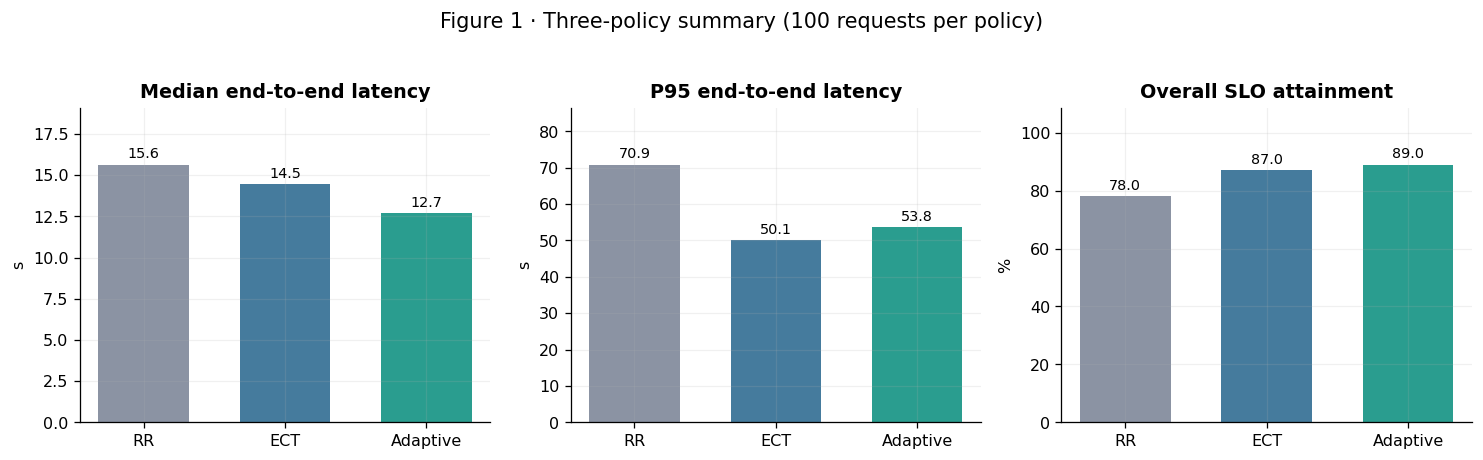

In [2]:
all_rows = summary.loc[summary['group'].eq('all')].set_index('policy').loc[policy_order]
metrics = pd.DataFrame({
    'Median E2E (s)':all_rows['median_e2e_s'],
    'P95 E2E (s)':all_rows['p95_e2e_s'],
    'Median TTFT (s)':all_rows['median_ttft_s'],
    'Overall SLO (%)':all_rows['overall_slo_attainment']*100,
    'Throughput (req/s)':all_rows['req_s'],
    'Success':all_rows['success'].astype(int).astype(str)+'/'+all_rows['requests'].astype(int).astype(str),
})
metrics.index = metrics.index.map(policy_names)
display(metrics.round(3))
fig, axes = plt.subplots(1, 3, figsize=(13,3.8))
for ax, (metric, title, unit) in zip(axes,[
    ('median_e2e_s','Median end-to-end latency','s'),
    ('p95_e2e_s','P95 end-to-end latency','s'),
    ('overall_slo_attainment','Overall SLO attainment','%')]):
    vals = all_rows[metric].to_numpy() * (100 if unit=='%' else 1)
    bars = ax.bar([policy_names[p] for p in policy_order],vals,color=[colors[p] for p in policy_order],width=.64)
    ax.set_title(title);ax.set_ylabel(unit)
    ax.set_ylim(0, max(vals)*1.22)
    for bar, val in zip(bars, vals): ax.text(bar.get_x()+bar.get_width()/2,val+max(vals)*.025,f'{val:.1f}',ha='center',fontsize=9)
fig.suptitle('Figure 1 · Three-policy summary (100 requests per policy)',fontsize=13,y=1.04)
fig.tight_layout();plt.show()

## 5. Latency distribution

Adaptive shifts typical requests toward lower latency, but **ECT still has the shorter P95 tail**.


/tmp/ipykernel_1431/4243605260.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box=axes[1].boxplot([requests.loc[requests.policy.eq(p),'e2e_s'].dropna().values for p in policy_order],


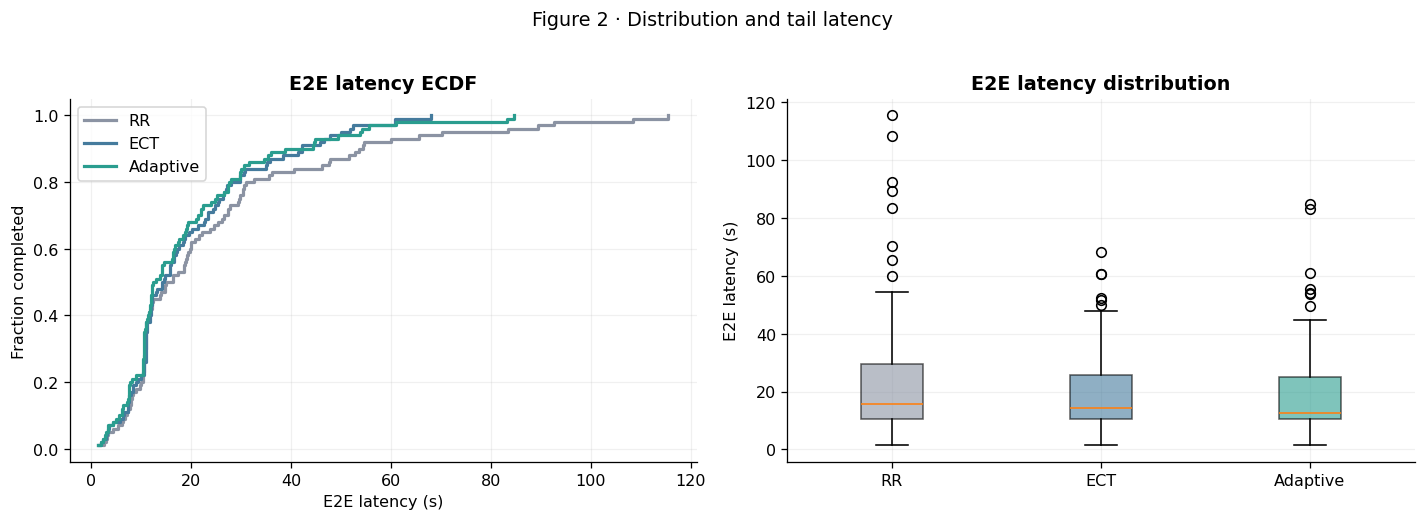

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12.5,4.4))
for p in policy_order:
    vals=np.sort(requests.loc[requests.policy.eq(p),'e2e_s'].dropna().to_numpy())
    axes[0].step(vals,np.arange(1,len(vals)+1)/len(vals),where='post',label=policy_names[p],color=colors[p],lw=2)
axes[0].set_title('E2E latency ECDF');axes[0].set_xlabel('E2E latency (s)');axes[0].set_ylabel('Fraction completed');axes[0].legend()
box=axes[1].boxplot([requests.loc[requests.policy.eq(p),'e2e_s'].dropna().values for p in policy_order],
                    labels=[policy_names[p] for p in policy_order],patch_artist=True,showfliers=True)
for artist,p in zip(box['boxes'],policy_order): artist.set_facecolor(colors[p]);artist.set_alpha(.60)
axes[1].set_title('E2E latency distribution');axes[1].set_ylabel('E2E latency (s)')
fig.suptitle('Figure 2 · Distribution and tail latency',y=1.02)
fig.tight_layout();plt.show()

## 6. Results by modality

Adaptive improves SLO attainment for **chat and text**, but trails ECT on **image and audio**. The per-modality samples are small.


policy,RR,ECT,Adaptive
group,,,
chat,77.3,86.4,93.2
text,81.8,86.4,90.9
image,89.5,89.5,84.2
audio,60.0,86.7,80.0


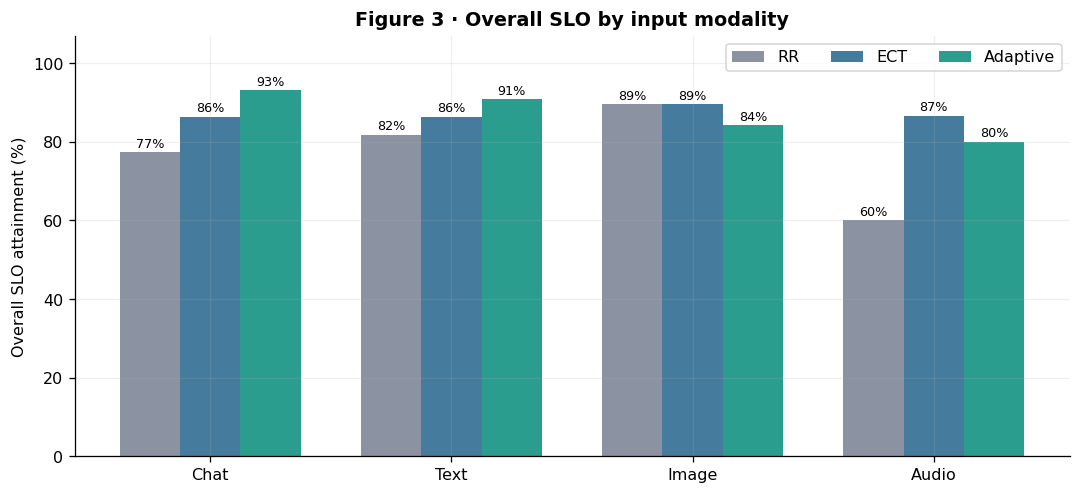

In [4]:
modalities=['chat','text','image','audio']
mod=summary.loc[summary.group.isin(modalities)].copy()
mod['overall_slo_pct']=mod['overall_slo_attainment']*100
pivot=mod.pivot(index='group',columns='policy',values='overall_slo_pct').reindex(index=modalities,columns=policy_order)
display(pivot.rename(columns=policy_names).round(1))
fig,ax=plt.subplots(figsize=(9.5,4.4))
x=np.arange(len(modalities));width=.25
for i,p in enumerate(policy_order):
    bars=ax.bar(x+(i-1)*width,pivot[p].to_numpy(),width,label=policy_names[p],color=colors[p]);
    for bar in bars:ax.annotate(f'{bar.get_height():.0f}%',(bar.get_x()+bar.get_width()/2,bar.get_height()),xytext=(0,3),textcoords='offset points',ha='center',fontsize=8)
ax.set_xticks(x, [m.title() for m in modalities]);ax.set_ylabel('Overall SLO attainment (%)');ax.set_ylim(0,107)
ax.set_title('Figure 3 · Overall SLO by input modality');ax.legend(ncol=3)
fig.tight_layout();plt.show()

## 7. Routing decisions

ECT sends **75%** of requests to AMD; Adaptive sends **52%**. The difference reflects workload-aware decisions, not necessarily better balance by itself.


node,c7a.2xlarge,c7i.2xlarge
policy,,
RR,50,50
ECT,75,25
Adaptive,52,48


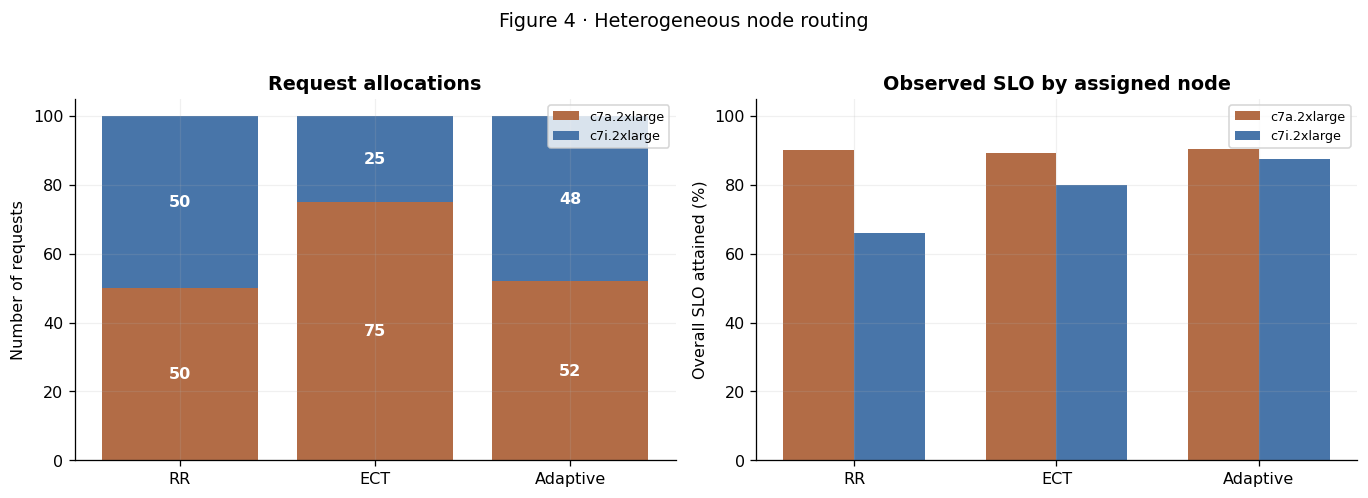

In [5]:
alloc=pd.crosstab(requests['policy'],requests['node']).reindex(policy_order)
display(alloc.rename(index=policy_names))
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
bottom=np.zeros(len(policy_order))
for node,c in zip(['c7a.2xlarge','c7i.2xlarge'],['#b26c46','#4875a9']):
    y=alloc[node].to_numpy()
    bars=axes[0].bar([policy_names[p] for p in policy_order],y,bottom=bottom,label=node,color=c)
    for idx,n in enumerate(y):axes[0].text(idx,bottom[idx]+n/2,str(int(n)),ha='center',va='center',color='white',weight='bold')
    bottom+=y
axes[0].set_ylabel('Number of requests');axes[0].set_title('Request allocations');axes[0].legend(fontsize=8)
slo_node=requests.groupby(['policy','node'])['overall_slo_met'].mean().mul(100).unstack().reindex(policy_order)
for i,node in enumerate(slo_node.columns):
    axes[1].bar(np.arange(3)+(i-.5)*.35,slo_node[node].to_numpy(),.35,label=node,color=['#b26c46','#4875a9'][i])
axes[1].set_xticks(np.arange(3),[policy_names[p] for p in policy_order]);axes[1].set_ylabel('Overall SLO attained (%)');axes[1].set_ylim(0,105)
axes[1].set_title('Observed SLO by assigned node');axes[1].legend(fontsize=8)
fig.suptitle('Figure 4 · Heterogeneous node routing',y=1.02);fig.tight_layout();plt.show()

## 8. SLO breakdown

Overall SLO requires **completion, TTFT, and TPOT** to pass. The component view shows where each policy still misses its targets.


,Completion,TTFT,TPOT,All three
policy,,,,
RR,93.0,87.0,90.0,78.0
ECT,99.0,94.0,93.0,87.0
Adaptive,98.0,95.0,94.0,89.0


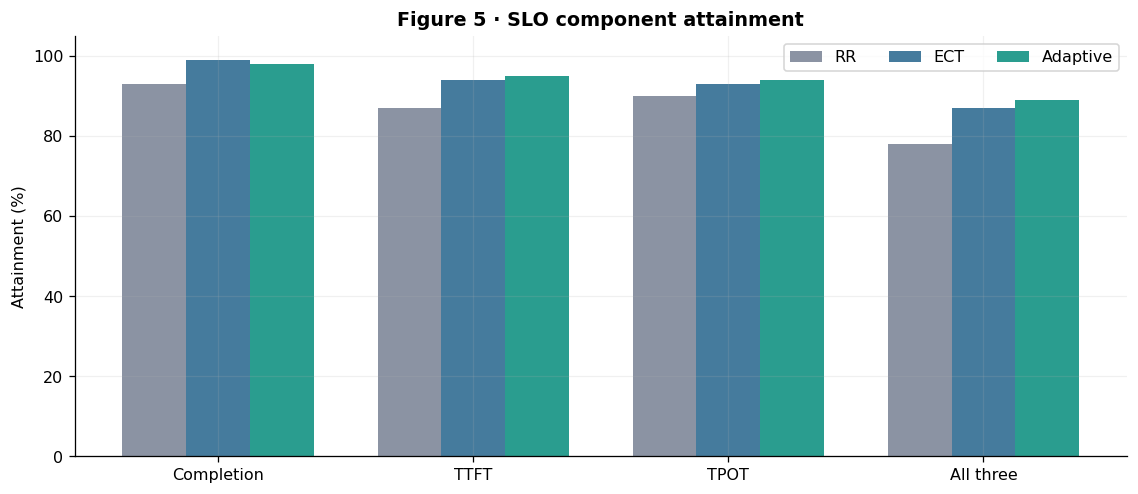

In [6]:
slo_cols={'completion_slo_met':'Completion','ttft_slo_met':'TTFT','tpot_slo_met':'TPOT','overall_slo_met':'All three'}
slo_table=requests.groupby('policy')[list(slo_cols)].mean().mul(100).reindex(policy_order)
display(slo_table.rename(index=policy_names,columns=slo_cols).round(1))
fig,ax=plt.subplots(figsize=(10,4.4));x=np.arange(4);width=.25
for i,p in enumerate(policy_order):
    ax.bar(x+(i-1)*width,slo_table.loc[p].to_numpy(),width,color=colors[p],label=policy_names[p])
ax.set_xticks(x,list(slo_cols.values()));ax.set_ylim(0,105);ax.set_ylabel('Attainment (%)');ax.set_title('Figure 5 · SLO component attainment');ax.legend(ncol=3)
fig.tight_layout();plt.show()

## 9. Prediction error

Predictions are imperfect. **RR/ECT and Adaptive use different predictors**, so treat this as a diagnostic rather than a controlled model comparison.


,MAE_s,Bias_s,RMSE_s
policy,,,
RR,11.49,-10.42,20.25
ECT,8.38,-7.14,12.55
Adaptive,5.00,-2.73,8.66


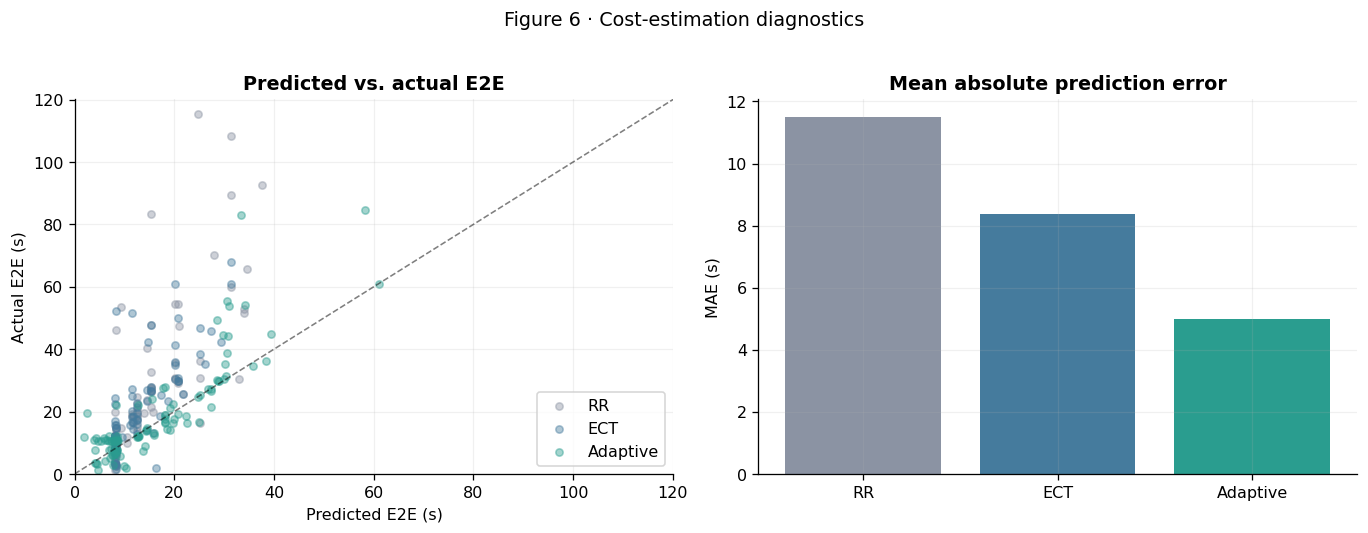

In [7]:
pred=requests.dropna(subset=['predicted_e2e_s','e2e_s']).copy()
pred['error_s']=pred['predicted_e2e_s']-pred['e2e_s']
err=pred.groupby('policy').agg(MAE_s=('error_s',lambda x: x.abs().mean()),
                               Bias_s=('error_s','mean'),RMSE_s=('error_s',lambda x:np.sqrt(np.mean(x**2)))).reindex(policy_order)
display(err.rename(index=policy_names).round(2))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for p in policy_order:
    r=pred[pred.policy.eq(p)];axes[0].scatter(r.predicted_e2e_s,r.e2e_s,alpha=.43,s=21,color=colors[p],label=policy_names[p])
lim=max(pred['predicted_e2e_s'].max(),pred['e2e_s'].max())*1.04
axes[0].plot([0,lim],[0,lim],ls='--',color='black',alpha=.5,lw=1);axes[0].set_xlim(0,lim);axes[0].set_ylim(0,lim)
axes[0].set_xlabel('Predicted E2E (s)');axes[0].set_ylabel('Actual E2E (s)');axes[0].set_title('Predicted vs. actual E2E');axes[0].legend()
axes[1].bar([policy_names[p] for p in policy_order],err.MAE_s,color=[colors[p] for p in policy_order])
axes[1].set_title('Mean absolute prediction error');axes[1].set_ylabel('MAE (s)')
fig.suptitle('Figure 6 · Cost-estimation diagnostics',y=1.02);fig.tight_layout();plt.show()

## 10. Adaptive runtime checks

**100 starts, 100 completions, 100 feedback updates.** The log also shows overlapping requests and full two-slot reservations.


,Observed log count
Calibration cache hits,1
HTTP starts,100
HTTP completions,100
Online-feedback events,100
Router DISPATCH records,100
Full 2/2 node reservations,20
Slot-full candidate skips,16


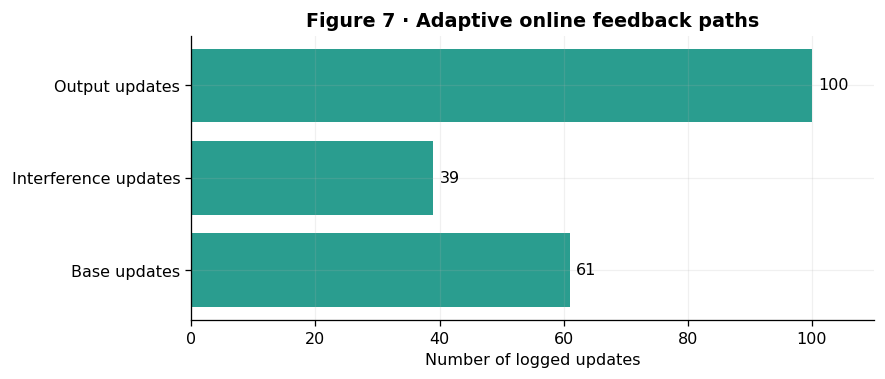

In [8]:
patterns={
    'Calibration cache hits':r'CALIBRATION_CACHE_HIT',
    'HTTP starts':r'HTTP_START\b',
    'HTTP completions':r'HTTP_DONE\b',
    'Online-feedback events':r'ONLINE_FEEDBACK req=',
    'Router DISPATCH records':r'\[router\.router\] DISPATCH req=',
    'Full 2/2 node reservations':r'running=2/2',
    'Slot-full candidate skips':r'CANDIDATE_SKIP',
}
# Use literal log tokens for the boundary-sensitive counters.
counts={
    'Calibration cache hits':adaptive_log.count('CALIBRATION_CACHE_HIT'),
    'HTTP starts':adaptive_log.count('HTTP_START'),
    'HTTP completions':adaptive_log.count('HTTP_DONE'),
    'Online-feedback events':adaptive_log.count('ONLINE_FEEDBACK req='),
    'Router DISPATCH records':len(re.findall(r'\[router\.router\] DISPATCH req=',adaptive_log)),
    'Full 2/2 node reservations':adaptive_log.count('running=2/2'),
    'Slot-full candidate skips':adaptive_log.count('CANDIDATE_SKIP'),
}
display(pd.DataFrame.from_dict(counts,orient='index',columns=['Observed log count']))
feedback=pd.Series({
    'Base updates':len(re.findall(r'ONLINE_FEEDBACK req=.*base=True',adaptive_log)),
    'Interference updates':len(re.findall(r'ONLINE_FEEDBACK req=.*interference=True',adaptive_log)),
    'Output updates':len(re.findall(r'ONLINE_FEEDBACK req=.*output=True',adaptive_log))
})
fig,ax=plt.subplots(figsize=(7.8,3.4))
ax.barh(feedback.index,feedback.values,color='#2a9d8f')
for i,v in enumerate(feedback.values):ax.text(v+1,i,str(v),va='center')
ax.set_xlim(0,110);ax.set_xlabel('Number of logged updates');ax.set_title('Figure 7 · Adaptive online feedback paths')
fig.tight_layout();plt.show()

## 11. Concurrency in practice

Overlapping request intervals confirm **concurrent in-flight execution**; they do not imply dedicated CPU resources per request.


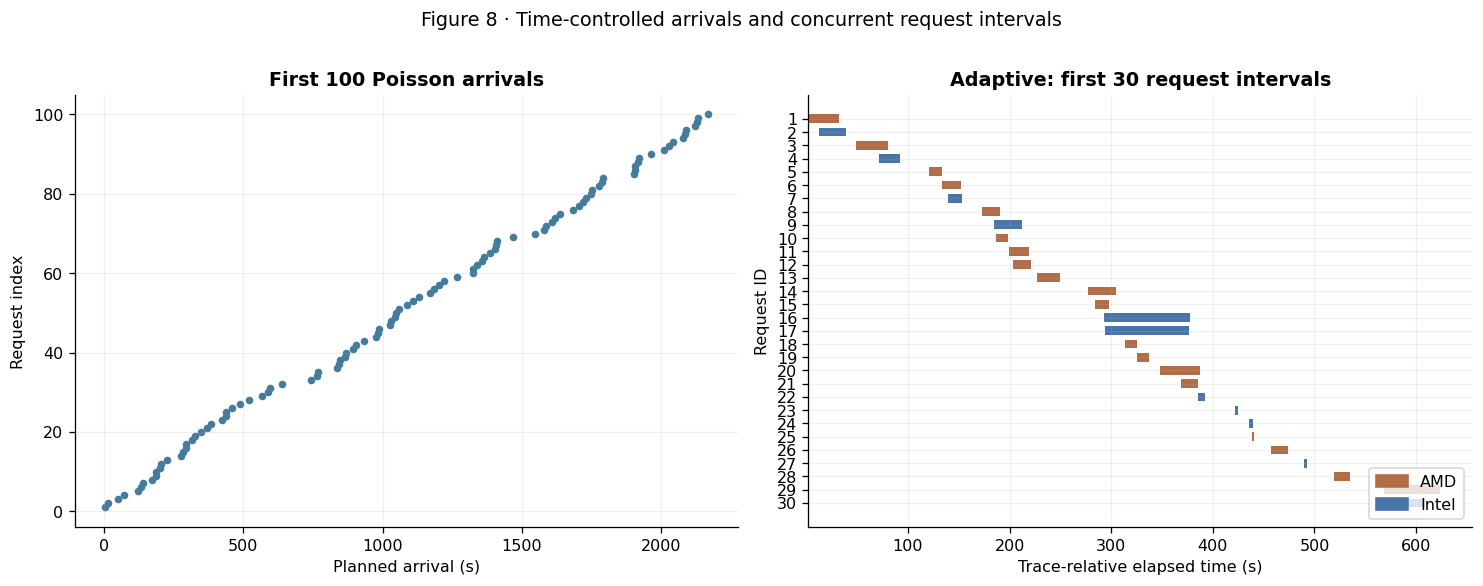

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
t=trace.iloc[:100].copy();axes[0].scatter(t.arrival_s,np.arange(1,101),s=14,color='#457b9d')
axes[0].set_xlabel('Planned arrival (s)');axes[0].set_ylabel('Request index');axes[0].set_title('First 100 Poisson arrivals')
a=requests[requests.policy.eq('adaptive')].sort_values('arrival_s').head(30).copy()
for y,(_,row) in enumerate(a.iterrows()):
    start=float(row['sent_s']);duration=float(row['e2e_s'])
    axes[1].barh(y,duration,left=start,height=.65,color='#b26c46' if row['node']=='c7a.2xlarge' else '#4875a9')
axes[1].invert_yaxis();axes[1].set_yticks(range(len(a)),[str(int(v)) for v in a['id']]);axes[1].set_xlabel('Trace-relative elapsed time (s)')
axes[1].set_ylabel('Request ID');axes[1].set_title('Adaptive: first 30 request intervals')
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color='#b26c46',label='AMD'),Patch(color='#4875a9',label='Intel')],loc='lower right')
fig.suptitle('Figure 8 · Time-controlled arrivals and concurrent request intervals',y=1.01)
fig.tight_layout();plt.show()

## 12. Takeaways

- **Adaptive wins on typical latency and SLO:** median E2E **12.7 s**, overall SLO **89%** (ECT: **14.5 s**, **87%**; RR: **15.6 s**, **78%**).
- **ECT wins at the tail:** P95 E2E **50.1 s**, versus **53.8 s** for Adaptive.
- **The gain is workload-dependent:** chat/text improve under Adaptive, while image/audio do not consistently improve.

**Next:** Repeat across seeds and load levels; investigate Adaptive's **11 SLO misses** and its higher P95 before changing the scheduling policy.
